In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
import warnings as w
w.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv('../Data/car_fuel_efficiency_2026.csv')
display(df.head())
df.info() 


# Split before computing any preprocessing statistics.
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - (n_val + n_test)

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy()
df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
df_test = df.iloc[idx[n_train + n_val:n_train + n_val + n_test]].copy()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  str    
 2   fuel_type            10000 non-null  str    
 3   drivetrain           10000 non-null  str    
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 859.5 KB


In [4]:
df = df.drop(columns=['drivetrain', 'fuel_type', 'origin', 'num_doors','num_cylinders', 'acceleration'])

In [5]:
df.columns


Index(['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight',
       'fuel_efficiency_mpg'],
      dtype='str')

In [6]:
print(df.head())

   model_year  engine_displacement  horsepower  vehicle_weight  \
0        2006                 2180       243.0            3870   
1        2008                 2390       272.0            4210   
2        1996                 2320       267.0            4240   
3        1989                 2130       258.0            4490   
4        1994                 2580       304.0            4510   

   fuel_efficiency_mpg  
0                 31.9  
1                 31.3  
2                 27.5  
3                 28.5  
4                 31.0  


In [7]:
df.dtypes

model_year               int64
engine_displacement      int64
horsepower             float64
vehicle_weight           int64
fuel_efficiency_mpg    float64
dtype: object

In [8]:
df.shape

(10000, 5)

In [9]:
display(df.head())

,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
0,2006,2180,243.0,3870,31.9
1,2008,2390,272.0,4210,31.3
2,1996,2320,267.0,4240,27.5
3,1989,2130,258.0,4490,28.5
4,1994,2580,304.0,4510,31.0


In [10]:
df.nunique()

model_year              50
engine_displacement    127
horsepower             153
vehicle_weight         176
fuel_efficiency_mpg    188
dtype: int64

In [11]:
display(df.isnull().sum())

model_year               0
engine_displacement      0
horsepower             877
vehicle_weight           0
fuel_efficiency_mpg      0
dtype: int64

In [29]:
df_zero = df.copy()
df_mean = df.copy()

horsepower_mean = df_train['horsepower'].mean()
df_zero['horsepower'] = df_zero['horsepower'].fillna(0)
df_mean['horsepower'] = df_mean['horsepower'].fillna(horsepower_mean)

In [13]:
print(df.nunique()) 
print(df_zero.isnull().sum())
print(df_mean.isnull().sum())

model_year              50
engine_displacement    127
horsepower             153
vehicle_weight         176
fuel_efficiency_mpg    188
dtype: int64
model_year             0
engine_displacement    0
horsepower             0
vehicle_weight         0
fuel_efficiency_mpg    0
dtype: int64
model_year             0
engine_displacement    0
horsepower             0
vehicle_weight         0
fuel_efficiency_mpg    0
dtype: int64


In [14]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - (n_val + n_test)

# Split first so preprocessing statistics come only from the training data.
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy()
df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
df_test = df.iloc[idx[n_train + n_val:n_train + n_val + n_test]].copy()

In [15]:
(n, n_train, n_val, n_test)

(10000, 6000, 2000, 2000)

In [16]:
df.iloc[:10]

,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
0,2006,2180,243.0,3870,31.9
1,2008,2390,272.0,4210,31.3
2,1996,2320,267.0,4240,27.5
3,1989,2130,258.0,4490,28.5
4,1994,2580,304.0,4510,31.0
5,2007,2290,266.0,4260,31.2
6,1992,2270,250.0,4310,26.8
7,2005,2370,279.0,4090,30.2
8,1997,2330,251.0,4230,30.9
9,2004,2330,280.0,4620,31.2


<Axes: xlabel='horsepower', ylabel='Count'>

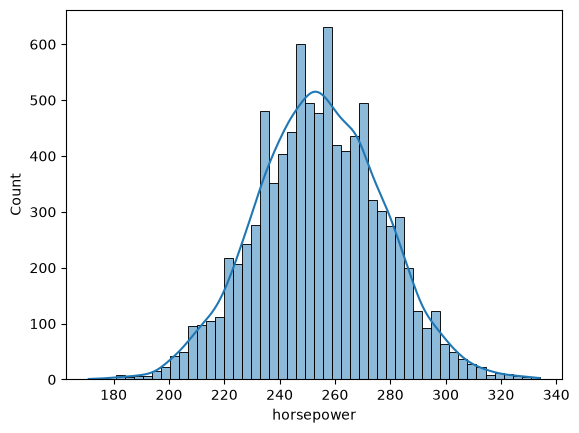

In [17]:
sns.histplot(df['horsepower'], kde=True, bins=50) 

In [18]:
df['horsepower'].median()

np.float64(254.0)

In [19]:
df_zero.dtypes

model_year               int64
engine_displacement      int64
horsepower             float64
vehicle_weight           int64
fuel_efficiency_mpg    float64
dtype: object

In [20]:
df_zero.columns

Index(['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight',
       'fuel_efficiency_mpg'],
      dtype='str')

In [21]:
df_mean.dtypes

model_year               int64
engine_displacement      int64
horsepower             float64
vehicle_weight           int64
fuel_efficiency_mpg    float64
dtype: object

In [22]:
base_zero = df_zero.copy()
base_mean = df_mean.copy() 

X_zero = base_zero.drop(['fuel_efficiency_mpg'], axis=1) 
X_mean = base_mean.drop(['fuel_efficiency_mpg'], axis=1)  
y_zero = base_zero['fuel_efficiency_mpg'] 
y_mean = base_mean['fuel_efficiency_mpg'] 

In [23]:
# One-hot encode categorical predictors. Impute remaining missing values using
# training-set means only (acceleration is also missing in the source data).
X_zero_model = pd.get_dummies(X_zero, drop_first=True, dtype=float)
X_mean_model = pd.get_dummies(X_mean, drop_first=True, dtype=float)
X_zero_model = X_zero_model.fillna(X_zero_model.loc[df_train.index].mean())
X_mean_model = X_mean_model.fillna(X_mean_model.loc[df_train.index].mean())

# LinearRegression is ordinary least squares (no regularization).
model_zero = LinearRegression()
model_zero.fit(X_zero_model.loc[df_train.index], y_zero.loc[df_train.index])

model_mean = LinearRegression()
model_mean.fit(X_mean_model.loc[df_train.index], y_mean.loc[df_train.index])

print(f"base_zero training R²: {model_zero.score(X_zero_model.loc[df_train.index], y_zero.loc[df_train.index]):.4f}")
print(f"base_mean training R²: {model_mean.score(X_mean_model.loc[df_train.index], y_mean.loc[df_train.index]):.4f}")

base_zero training R²: 0.4379
base_mean training R²: 0.4390


In [24]:
# Tune L2 regularization strength on base_zero using validation RMSE.
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]
regularized_models = {}
validation_results = []

X_zero_train = X_zero_model.loc[df_train.index]
y_zero_train = y_zero.loc[df_train.index]
X_zero_val = X_zero_model.loc[df_val.index]
y_zero_val = y_zero.loc[df_val.index]

for r in r_values:
    # r=0 is ordinary least squares; positive r values use Ridge (L2).
    model = LinearRegression() if r == 0 else Ridge(alpha=r)
    model.fit(X_zero_train, y_zero_train)
    val_predictions = model.predict(X_zero_val)
    rmse = np.sqrt(mean_squared_error(y_zero_val, val_predictions))

    regularized_models[r] = model
    validation_results.append({'r': r, 'validation_rmse': rmse})

validation_results = pd.DataFrame(validation_results).sort_values('validation_rmse')
display(validation_results)

best_r = validation_results.iloc[0]['r']
print(f"Best r: {best_r}; validation RMSE: {validation_results.iloc[0]['validation_rmse']:.4f}")

,r,validation_rmse
0,0.00,2.205293
1,0.01,2.205293
2,0.10,2.205293
3,1.00,2.205293
4,5.00,2.205293
5,10.00,2.205293
6,100.00,2.205294


Best r: 0.0; validation RMSE: 2.2053


In [25]:
# Measure validation RMSE variability across different train/validation/test splits.
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

# Zero-impute all missing predictors, then one-hot encode categorical columns.
X_zero_seed = pd.get_dummies(
    df.drop(columns=['fuel_efficiency_mpg']), drop_first=True, dtype=float
).fillna(0)
y = df['fuel_efficiency_mpg']

validation_rmse_scores = []

for seed in seeds:
    indices = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(indices)

    train_idx = indices[:n_train]
    val_idx = indices[n_train:n_train + n_val]
    # Remaining indices form the 20% test split; kept aside during validation.

    model = LinearRegression()
    model.fit(X_zero_seed.iloc[train_idx], y.iloc[train_idx])
    val_predictions = model.predict(X_zero_seed.iloc[val_idx])
    score = np.sqrt(mean_squared_error(y.iloc[val_idx], val_predictions))
    validation_rmse_scores.append(score)

print('Validation RMSE scores:', validation_rmse_scores)
std = np.std(validation_rmse_scores)
print('Standard deviation:', round(std, 3))

Validation RMSE scores: [np.float64(2.239204143050754), np.float64(2.2021128210837335), np.float64(2.163419778753079), np.float64(2.2043588768529316), np.float64(2.201880094331772), np.float64(2.2457851509081426), np.float64(2.269721207951652), np.float64(2.1907945999354204), np.float64(2.216611201694418), np.float64(2.2070365928234095)]
Standard deviation: 0.029


In [26]:
# With seed 9, combine the 60% train and 20% validation partitions,
# then evaluate an L2-regularized model (r = 0.001) on the held-out test set.
seed = 9
indices = np.arange(len(df))
np.random.seed(seed)
np.random.shuffle(indices)

n_test = int(len(df) * 0.2)
test_idx = indices[-n_test:]
train_val_idx = indices[:-n_test]

train_val_df = df.iloc[train_val_idx]
test_df = df.iloc[test_idx]
y_train_val = train_val_df['fuel_efficiency_mpg']
y_test = test_df['fuel_efficiency_mpg']

X_train_val = pd.get_dummies(
    train_val_df.drop(columns=['fuel_efficiency_mpg']), drop_first=True, dtype=float
)
X_test = pd.get_dummies(
    test_df.drop(columns=['fuel_efficiency_mpg']), drop_first=True, dtype=float
).reindex(columns=X_train_val.columns, fill_value=0)

X_train_val = X_train_val.fillna(0)
X_test = X_test.fillna(0)

model_r_001 = Ridge(alpha=0.001)
model_r_001.fit(X_train_val, y_train_val)
test_predictions = model_r_001.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
print('Test RMSE:', test_rmse)

Test RMSE: 2.235774702813793


In [27]:
df.describe()

,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
count,10000.000000,10000.000000,9123.000000,10000.000000,10000.000000
mean,1999.549500,2268.807000,254.446016,4286.754000,29.997700
std,14.207925,183.447355,22.844613,266.212491,2.930245
min,1975.000000,1590.000000,171.000000,3320.000000,19.800000
25%,1987.000000,2150.000000,239.000000,4110.000000,28.000000
50%,2000.000000,2270.000000,254.000000,4280.000000,30.000000
75%,2012.000000,2390.000000,270.000000,4470.000000,31.900000
max,2024.000000,3110.000000,334.000000,5460.000000,41.200000


In [28]:
df.isnull().sum()

model_year               0
engine_displacement      0
horsepower             877
vehicle_weight           0
fuel_efficiency_mpg      0
dtype: int64

In [30]:
df_zero.isnull().sum()

model_year             0
engine_displacement    0
horsepower             0
vehicle_weight         0
fuel_efficiency_mpg    0
dtype: int64

In [31]:
df_zero_full_train, df_zero_full_test = train_test_split(df_zero, test_size=0.2, random_state=1) 
df_zero_train, df_zero_val = train_test_split(df_zero_full_train, test_size=0.25, random_state=1)  # 0.25 x 0.8 = 0.2 

In [38]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Separate the target, then convert each feature dataframe to record dictionaries.
y_zero_train = df_zero_train['fuel_efficiency_mpg']
y_zero_val = df_zero_val['fuel_efficiency_mpg']
y_zero_test = df_zero_full_test['fuel_efficiency_mpg']

X_zero_train_dict = df_zero_train.drop(columns='fuel_efficiency_mpg').to_dict(orient='records')
X_zero_val_dict = df_zero_val.drop(columns='fuel_efficiency_mpg').to_dict(orient='records')
X_zero_test_dict = df_zero_full_test.drop(columns='fuel_efficiency_mpg').to_dict(orient='records')

# Learn the feature mapping from training data only; reuse it for validation and test.
dv = DictVectorizer(sparse=True)
X_zero_train_matrix = dv.fit_transform(X_zero_train_dict)
X_zero_val_matrix = dv.transform(X_zero_val_dict)
X_zero_test_matrix = dv.transform(X_zero_test_dict)

# Map encoded feature names (for example, 'origin=USA') to source columns ('origin').
feature_to_column = {
    feature: feature.partition('=')[0]
    for feature in dv.get_feature_names_out()
}
print("'origin=USA' maps to:", 'origin=USA'.partition('=')[0])

print('Train matrix:', X_zero_train_matrix.shape)
print('Validation matrix:', X_zero_val_matrix.shape)
print('Test matrix:', X_zero_test_matrix.shape)

# Fit a shallow regression tree and check its validation RMSE.
tree_model = DecisionTreeRegressor(max_depth=1, random_state=1)
tree_model.fit(X_zero_train_matrix, y_zero_train)
val_tree_predictions = tree_model.predict(X_zero_val_matrix)
val_tree_rmse = np.sqrt(mean_squared_error(y_zero_val, val_tree_predictions))
print('Validation RMSE (max_depth=1):', round(val_tree_rmse, 3))

# Report the root split as both its encoded feature and original column.
split_idx = tree_model.tree_.feature[0]
split_feature = dv.get_feature_names_out()[split_idx]
split_column = feature_to_column[split_feature]
split_threshold = tree_model.tree_.threshold[0]
print(f'Split: {split_feature} (original column: {split_column}) <= {split_threshold:.3f}')

# Compare random forests with different numbers of trees on the validation set.
n_estimators_values = [10, 50, 100, 150]
rf_models = {}
rf_results = []

for n_estimators in n_estimators_values:
    rf_model = RandomForestRegressor(
        n_estimators=n_estimators,
        random_state=1,
        n_jobs=-1,
    )
    rf_model.fit(X_zero_train_matrix, y_zero_train)
    val_rf_predictions = rf_model.predict(X_zero_val_matrix)
    val_rf_rmse = np.sqrt(mean_squared_error(y_zero_val, val_rf_predictions))

    rf_models[n_estimators] = rf_model
    rf_results.append({
        'n_estimators': n_estimators,
        'validation_rmse': val_rf_rmse,
    })

rf_results = pd.DataFrame(rf_results).sort_values('n_estimators')
display(rf_results)

'origin=USA' maps to: origin
Train matrix: (6000, 4)
Validation matrix: (2000, 4)
Test matrix: (2000, 4)
Validation RMSE (max_depth=1): 2.673
Split: model_year (original column: model_year) <= 1997.500


,n_estimators,validation_rmse
0,10,2.452854
1,50,2.369006
2,100,2.361006
3,150,2.360210


In [39]:
# Compare max_depth values across the requested n_estimators values.
max_depth_values = [10, 15, 20, 25]
n_estimators_values = [10, 50, 100, 150]
depth_search_results = []
depth_search_models = {}

for max_depth in max_depth_values:
    for n_estimators in n_estimators_values:
        model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=1,
            n_jobs=-1,
        )
        model.fit(X_zero_train_matrix, y_zero_train)
        predictions = model.predict(X_zero_val_matrix)
        validation_rmse = np.sqrt(mean_squared_error(y_zero_val, predictions))

        depth_search_models[(max_depth, n_estimators)] = model
        depth_search_results.append({
            'max_depth': max_depth,
            'n_estimators': n_estimators,
            'validation_rmse': validation_rmse,
        })

# Show each combination, then average the four RMSE values for each max_depth.
depth_search_results = pd.DataFrame(depth_search_results)
display(depth_search_results.sort_values(['max_depth', 'n_estimators']))

mean_rmse_by_depth = (
    depth_search_results.groupby('max_depth', as_index=False)['validation_rmse']
    .mean()
    .rename(columns={'validation_rmse': 'mean_validation_rmse'})
    .sort_values('mean_validation_rmse')
)
display(mean_rmse_by_depth)

best_max_depth = int(mean_rmse_by_depth.iloc[0]['max_depth'])
print('Best max_depth by mean validation RMSE:', best_max_depth)

,max_depth,n_estimators,validation_rmse
0,10,10,2.331699
1,10,50,2.307585
2,10,100,2.300238
3,10,150,2.298042
4,15,10,2.434155
5,15,50,2.358863
6,15,100,2.350578
7,15,150,2.347577
8,20,10,2.455752
9,20,50,2.373174


,max_depth,mean_validation_rmse
0,10,2.309391
1,15,2.372794
3,25,2.385977
2,20,2.388380


Best max_depth by mean validation RMSE: 10


In [40]:
# Train the requested random forest and inspect its impurity-based feature importances.
importance_model = RandomForestRegressor(
    n_estimators=10,
    max_depth=20,
    random_state=1,
    n_jobs=-1,
)
importance_model.fit(X_zero_train_matrix, y_zero_train)

feature_names = dv.get_feature_names_out()
feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'original_column': [feature.partition('=')[0] for feature in feature_names],
    'importance': importance_model.feature_importances_,
}).sort_values('importance', ascending=False, ignore_index=True)

display(feature_importance_df)

,feature,original_column,importance
0,model_year,model_year,0.353210
1,vehicle_weight,vehicle_weight,0.314218
2,engine_displacement,engine_displacement,0.173961
3,horsepower,horsepower,0.158611


In [41]:
import xgboost as xgb

# Build sparse DMatrix objects for training and validation.
dtrain = xgb.DMatrix(X_zero_train_matrix, label=y_zero_train)
dval = xgb.DMatrix(X_zero_val_matrix, label=y_zero_val)
watchlist = [(dtrain, 'train'), (dval, 'validation')]

base_xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

# Compare eta=0.3 with eta=0.1, training each model for 100 rounds.
eta_results = []
xgb_models = {}

for eta in [0.3, 0.1]:
    xgb_params = {**base_xgb_params, 'eta': eta}
    evals_result = {}
    xgb_model = xgb.train(
        params=xgb_params,
        dtrain=dtrain,
        num_boost_round=100,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False,
    )

    validation_rmse = evals_result['validation']['rmse'][-1]
    eta_results.append({'eta': eta, 'validation_rmse': validation_rmse})
    xgb_models[eta] = xgb_model

eta_results = pd.DataFrame(eta_results).sort_values('validation_rmse')
display(eta_results)
best_eta = float(eta_results.iloc[0]['eta'])
print(f'Best eta: {best_eta} (validation RMSE: {eta_results.iloc[0]["validation_rmse"]:.4f})')

,eta,validation_rmse
1,0.1,2.299978
0,0.3,2.397657


Best eta: 0.1 (validation RMSE: 2.3000)
